# Where does the "n" answer come from? Five checks on `0×n = n` / `n×0 = n`

The dominant error on the 0-facts is answering the non-zero operand (`0×7 = 7`, DECISIONS #14, #44).
The expert review of November 2026 asked for three checks on what that answer means (DECISIONS #63-#66):

* **H1 — addition.** The child treats `n×0` as `n+0`. If so, the same children should also add on the
  *other* multiplications (`7×1 = 8`, `3×4 = 7`) more often than children who get the 0-facts right.
* **H2 — interference from the ×1 rule.** `n×1 = n` gives exactly the wrong answer for `n×0`. If a 1-fact
  shown just before the 0-fact raises the share of "n" answers, the ×1 rule is a plausible source.
* **H3 — speed.** Is the "n" answer fast (a rule fired automatically) or slow (a computation), compared with
  correct answers and with other wrong answers?

Two follow-up hypotheses (DECISIONS #68-#69):
* **H4 — copy the other operand.** The child over-applies "×0 and ×1 give back the other number". On a 1-fact the
  copy (`7×1 = 1`) and the addition (`7×1 = 8`) are different answers, so the two accounts can be told apart.
* **H5 — stable misconception or slip?** A belief makes children either never or almost always answer n; a slip
  spreads the n rate evenly across children.

Data: A998, ES_2025, ages 9-15 (age 8 has no 0-facts, #12), every (student, age) unit that met at least one
0-fact. The target 0-facts are those with n ≥ 2: `0×0` has no additive error (#15) and on `0×1` / `1×0` the
answer 1 is at once the additive, the copy and the 1-rule answer (#44), so neither can separate anything.

Sections
1. Data and coverage
2. H1 — addition hypothesis
3. H2 — interference from a preceding 1-fact
4. H3 — response time of the "n" answer
5. H4 — copy the other operand
6. H5 — stable misconception or slip
7. Summary

In [1]:
import logging, re, sys, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pyfixest.estimation import feols
from scipy.special import logsumexp
from scipy.stats import binom, spearmanr
from statsmodels.stats.contingency_tables import StratifiedTable

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
sys.path.insert(0, str(ROOT))
from binary_stats import tetrachoric_ci, wilson
from cached_query import cached_query
from paired_stats import holm, signed_rank
from plot_style import C_ONE, C_OTHER, C_ZERO, FONT_MED, paint_it_black, set_style

Q, PLOTS = ROOT / "queries", ROOT / "analysis" / "plots"; PLOTS.mkdir(exist_ok=True)
YEAR, FLOOR = "ES_2025", 1.2
AGES = list(range(9, 16))
GROUPS = ["n-error", "other 0-error", "0-correct"]                 # H1 groups, reference last
GCOL = {"n-error": C_ZERO, "other 0-error": plt.cm.viridis(0.6), "0-correct": C_OTHER}
CLASSES = ["correct", "= n", "other error"]                       # H3 answer classes
CCOL = {"correct": C_OTHER, "= n": C_ZERO, "other error": plt.cm.viridis(0.6)}
PREV = ["one", "zero", "division", "none", "retrieval"]            # H2 context, reference last
PCOL = {"one": C_ONE, "zero": C_ZERO, "division": "#7A7A7A", "none": "#D9D9D9", "retrieval": C_OTHER}
set_style()
for noisy in ("fontTools", "matplotlib.font_manager"):
    logging.getLogger(noisy).setLevel(logging.WARNING)
warnings.filterwarnings("ignore", message=".*singleton fixed effect.*")
warnings.filterwarnings("ignore", message="(?s).*multicollinearity.*")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 120)
fmt = lambda p: "< .001" if p < .001 else f"= {p:.3f}"


def cq(name, year=YEAR):
    s = (Q / name).read_text(encoding="utf-8")
    s = re.sub(r"'[A-Z_0-9-]+'(\s+-- \{YEAR\})", f"'{year}'\\1", s)
    return cached_query(Q / name, cache_dir=ROOT / "cache", sql_text=s)


def save(fig, stem):
    fig.savefig(PLOTS / f"{stem}.pdf", dpi=300, bbox_inches="tight")
    fig.savefig(PLOTS / f"{stem}.png", dpi=300, bbox_inches="tight")
    plt.close(fig)


def kraft(d):
    """Kraft (2020) education benchmarks on |d| (SD units): < .05 small, .05-.20 medium, >= .20 large."""
    a = abs(d)
    return "small" if a < .05 else "medium" if a < .20 else "large"


def d_from_or(o):
    """Logit-to-d conversion (Chinn 2000): d = ln(OR)·√3/π. Puts binary outcomes on the SD scale of Kraft."""
    return np.log(o) * np.sqrt(3) / np.pi


def or_from_pp(p0, beta_pp):
    """Odds ratio implied by a linear-probability effect beta (points) on a baseline rate p0 (points)."""
    p0, p1 = p0 / 100, (p0 + beta_pp) / 100
    return (p1 / (1 - p1)) / (p0 / (1 - p0))


def fe(fml, data, terms, cluster="student_uuid", weights=None):
    """feols with student-clustered SEs; returns the rows of `terms` from tidy()."""
    m = feols(fml, data=data, vcov={"CRV1": cluster}, weights=weights)
    t = m.tidy()
    return t.loc[[x for x in terms if x in t.index], ["Estimate", "Std. Error", "Pr(>|t|)", "2.5%", "97.5%"]] \
        .rename(columns={"Estimate": "b", "Std. Error": "se", "Pr(>|t|)": "p", "2.5%": "lo", "97.5%": "hi"})


def classify(df):
    """Answer class on a 0-fact with n >= 2: correct, '= n' (the non-zero operand), other error (incl. Help)."""
    n = df.left_factor + df.right_factor
    return np.select([df.statement_result.eq("Correct"), df.answer.eq(n)], CLASSES[:2], default=CLASSES[2])


def dummies(df, col, levels, prefix):
    for lv in levels:
        df[f"{prefix}_{lv.replace(' ', '_').replace('-', '_').replace('=', 'eq')}"] = df[col].eq(lv).astype(np.int8)
    return df


# ---------- helpers ----------
def build_groups(zk):
    g = zk.groupby("unit").agg(n_zero=("cls", "size"), any_n=("cls", lambda s: s.eq("= n").any()),
                               share_n=("cls", lambda s: s.eq("= n").mean()),
                               any_err=("cls", lambda s: s.ne("correct").any()))
    g["group"] = np.select([g.any_n, g.any_err], GROUPS[:2], default=GROUPS[2])
    # consistency definition (robustness): n on at least half of the 0-trials vs all correct
    g["group_consistent"] = np.select([g.share_n.ge(.5), ~g.any_err], ["n-error", "0-correct"], default="")
    g["nz_bin"] = pd.cut(g.n_zero, [0, 1, 2, 3, 5, 8, 1e9]).astype(str)
    return g


def h1_cells(f, g):
    tot = f[f.level.eq("total")].groupby("unit")[["n_resp", "n_err"]].sum()
    prof = (tot.n_err / tot.n_resp).rename("err_rate_nonzero")
    cells = f[f.level.eq("fact") & f.n_err_ans.gt(0)].copy()
    cells = cells.join(g[["group", "group_consistent", "nz_bin"]], on="unit").join(prof, on="unit")
    cells = cells[cells.group.notna()]
    cells["prof_dec"] = pd.qcut(cells.err_rate_nonzero.rank(method="first"), 10, labels=False).astype(str)
    a, b = cells.left_factor.astype(int), cells.right_factor.astype(int)
    cells["outcome"] = np.where(cells.ptype.eq("one"), "1-facts (n+1)", "retrieval (a+b)")
    cells = cells[~(a.eq(2) & b.eq(2))]
    a, b = cells.left_factor.astype(int), cells.right_factor.astype(int)
    cells["clean"] = cells.ptype.eq("retrieval") & ((a + b) % a).ne(0) & ((a + b) % b).ne(0)
    cells["op_age"] = cells.operation.astype(str) + "_" + cells.course_age.astype(str)
    cells["y"] = 100 * cells.n_add / cells.n_err_ans
    cells["y_rev"] = 100 * cells.n_add_rev / cells.n_err_ans
    p = cells.groupby("op_age").apply(lambda d: d.n_add.sum() / d.n_err_ans.sum(), include_groups=False)
    cells["expected"] = cells.n_err_ans * cells.op_age.map(p)
    return dummies(cells, "group", GROUPS[:2], "g")


def mh_or(d, gcol="group"):
    tabs = []
    for _, s in d[d[gcol].isin(["n-error", "0-correct"])].groupby("op_age"):
        t = s.groupby(gcol)[["n_add", "n_err_ans"]].sum()
        if len(t) == 2 and t.n_add.sum() > 0:
            ne, oc = t.loc["n-error"], t.loc["0-correct"]
            tabs.append(np.array([[ne.n_add, ne.n_err_ans - ne.n_add], [oc.n_add, oc.n_err_ans - oc.n_add]]) + .5)
    st = StratifiedTable(tabs)
    lo, hi = st.oddsratio_pooled_confint()
    return st.oddsratio_pooled, lo, hi


def h1_table(cells, g, f, subsets):
    """Per group: additive answers per 100 responses (raw, what a naive comparison sees) and per 100 answered
    errors, O/E, the adjusted LPM difference vs 0-correct, and the MH odds ratio (n-error vs 0-correct)."""
    tot = f[f.level.eq("total")].join(g.group, on="unit").groupby(["ptype", "group"])[["n_resp", "n_add"]].sum()
    rows, fits = [], {}
    for name, d, y in subsets:
        desc = d.groupby("group").agg(students_w_err=("unit", "nunique"), answered_err=("n_err_ans", "sum"),
                                      additive=("n_add", "sum"), expected=("expected", "sum"))
        pt = "one" if name.startswith("1-facts") else "retrieval" if name.startswith("retrieval (") else None
        desc["per_100_resp"] = 100 * tot.loc[pt].n_add / tot.loc[pt].n_resp if pt else np.nan
        desc["pct_of_errors"] = 100 * desc.additive / desc.answered_err
        desc["O/E"] = desc.additive / desc.expected
        r = fe(f"{y} ~ g_n_error + g_other_0_error | op_age + prof_dec + nz_bin", d,
               ["g_n_error", "g_other_0_error"], weights="n_err_ans")
        o, lo, hi = mh_or(d)
        base = desc.loc["0-correct", "pct_of_errors"]
        for grp in GROUPS:
            rr = {"outcome": name, "group": grp, **desc.loc[grp].to_dict()}
            key = {"n-error": "g_n_error", "other 0-error": "g_other_0_error"}.get(grp)
            if key in r.index:
                rr.update(adj_pp=r.loc[key, "b"], lo=r.loc[key, "lo"], hi=r.loc[key, "hi"], p=r.loc[key, "p"])
            if grp == "n-error":
                rr.update(MH_OR=o, OR_lo=lo, OR_hi=hi, d=d_from_or(o), kraft=kraft(d_from_or(o)))
            rows.append(rr)
        fits[name] = r
    return pd.DataFrame(rows).set_index(["outcome", "group"])


def plot_h1(cells, stem, what="Additive answer"):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=False)
    for ax, (name, d) in zip(axes, cells.groupby("outcome")):
        for i, grp in enumerate(GROUPS):
            s = d[d.group.eq(grp)].groupby("course_age")[["n_add", "n_err_ans"]].sum()
            s = s[s.n_err_ans.ge(30)]
            ci = np.array([wilson(k, n) for k, n in zip(s.n_add, s.n_err_ans)])
            x = s.index + (i - 1) * .18
            ax.errorbar(x, 100 * s.n_add / s.n_err_ans, yerr=100 * np.abs(ci.T - (s.n_add / s.n_err_ans).to_numpy()),
                        fmt="o-", color=GCOL[grp], mec="black", mew=.5, ms=8, capsize=3, label=grp)
        ax.set_title(f"{what} on {name}", fontsize=FONT_MED, color="black")
        ax.set_xticks(AGES); ax.set_xlabel("Age", fontsize=FONT_MED)
        ax.set_ylabel("% of answered errors", fontsize=FONT_MED); sns.despine(ax=ax)
    axes[0].legend(frameon=False, fontsize=13, title="Group (on the 0-facts)", title_fontsize=13)
    fig.text(.99, -.02, f"ES_2025, {cells.unit.nunique():,} students; 95% Wilson CI; cells with ≥ 30 errors",
             ha="right", fontsize=11)
    fig.tight_layout(); paint_it_black(axes); save(fig, stem)
    return fig


def plot_h2(zk, h2, stem):
    fig, axes = plt.subplots(1, 3, figsize=(22, 5.5), gridspec_kw={"width_ratios": [1, 1, 1.1]})
    ax = axes[0]
    s = zk.groupby("prev1c").agg(k=("y_n", lambda v: (v > 0).sum()), n=("y_n", "size")).loc[PREV]
    ci = np.array([wilson(k, n) for k, n in zip(s.k, s.n)])
    ax.bar(range(len(s)), 100 * s.k / s.n, color=[PCOL[p] for p in s.index], edgecolor="black", lw=.5)
    ax.errorbar(range(len(s)), 100 * s.k / s.n, yerr=100 * np.abs(ci.T - (s.k / s.n).to_numpy()), fmt="none",
                ecolor="black", capsize=4)
    ax.set_xticks(range(len(s)), [f"{p}\n{n / 1000:.0f}k" for p, n in zip(s.index, s.n)], fontsize=13)
    ax.set_ylabel('% of 0-fact answers "= n"', fontsize=FONT_MED); ax.set_title("A  Raw, by previous statement",
                                                                                 fontsize=FONT_MED, loc="left")
    ax = axes[1]
    d = h2[h2.spec.eq("unit FE") & h2.term.eq("p_one")].set_index("outcome").loc[["y_n", "y_other", "y_err"]]
    lab = {"y_n": '"= n"', "y_other": "other error", "y_err": "any error"}
    ax.errorbar(d.b, range(3), xerr=[d.b - d.lo, d.hi - d.b], fmt="o", color=C_ONE, mec="black", ms=10, capsize=4)
    ax.axvline(0, color="black", lw=.8); ax.set_yticks(range(3), [lab[i] for i in d.index]); ax.invert_yaxis()
    ax.set_xlabel("Previous = 1-fact vs retrieval (points)", fontsize=FONT_MED)
    ax.set_title("B  Within student, fact and position", fontsize=FONT_MED, loc="left")
    ax = axes[2]
    for i, (by, col, lab) in enumerate([("level", C_ONE, "Level (Q1 = lowest accuracy)"),
                                        ("speed", "#7A7A7A", "Speed (Q1 = fastest)")]):
        q = quint.loc[by]
        x = np.arange(5) + (i - .5) * .22
        ax.errorbar(x, q.b, yerr=[q.b - q.lo, q.hi - q.b], fmt="o", color=col, mec="black", ms=9, capsize=4, label=lab)
    ax.axhline(0, color="black", lw=.8); ax.set_xticks(range(5), [f"Q{i}" for i in range(1, 6)])
    ax.set_ylabel("Previous 1-fact effect (points)", fontsize=FONT_MED)
    ax.set_xlabel("Quintile, measured on retrieval facts", fontsize=FONT_MED)
    ax.set_title("C  By student level and speed", fontsize=FONT_MED, loc="left")
    ax.legend(frameon=False, fontsize=12, loc="upper right")
    for a in axes:
        sns.despine(ax=a)
    fig.text(.99, -.02, f"ES_2025, ages 9-15, {len(zk):,} 0-fact responses, {zk.unit.nunique():,} students "
             f"(C: {zc.unit.nunique():,} with controls); 95% CI (Wilson in A, student-clustered in B, C)",
             ha="right", fontsize=11)
    fig.tight_layout(); paint_it_black(axes); save(fig, stem)
    return fig


def rt_data(z, mode):
    d = z[z.rt_seconds.gt(0) & ~(z.cls.eq("other error") & z.answer.isna())].copy()
    if mode == "symmetric":
        d = d[d.rt_seconds.ge(FLOOR)]
    elif mode == "#7":
        d = d[d.fast_wrong.eq(0)]
    d["lnrt"] = np.log(d.rt_seconds)
    return dummies(d, "cls", ["= n", "other error"], "c")


def paired(d, a, b):
    m = d[d.cls.isin([a, b])].groupby(["unit", "cls"]).lnrt.median().unstack().dropna()
    r = signed_rank(m[a] - m[b])
    return {"contrast": f"{a} − {b}", "students": r["students"], "ratio_median": np.exp(r["med_diff"]),
            "lo": np.exp(r["ci_lo"]), "hi": np.exp(r["ci_hi"]), "pct_slower": r["pct_slower"], "r_rb": r["r_rb"],
            "p": r["p"]}


def plot_h3(d3, by_age, stem):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
    ax = axes[0]
    for i, c in enumerate(CLASSES):
        s = d3[d3.cls.eq(c)].groupby("course_age").rt_seconds
        q = s.quantile([.25, .5, .75]).unstack()
        x = q.index + (i - 1) * .18
        ax.errorbar(x, q[.5], yerr=[q[.5] - q[.25], q[.75] - q[.5]], fmt="o-", color=CCOL[c], mec="black", mew=.5,
                    ms=8, capsize=3, label=c)
    ax.set_xticks(AGES); ax.set_xlabel("Age", fontsize=FONT_MED); ax.set_ylabel("RT (s), median and IQR",
                                                                                  fontsize=FONT_MED)
    ax.set_title("A  Response time by answer", fontsize=FONT_MED, loc="left"); ax.legend(frameon=False, fontsize=13)
    ax = axes[1]
    ax.errorbar(by_age.index, by_age.b, yerr=[by_age.b - by_age.lo, by_age.hi - by_age.b], fmt="o", color=C_ZERO,
                mec="black", ms=9, capsize=4)
    ax.axhline(0, color="black", lw=.8); ax.set_xticks(AGES); ax.set_xlabel("Age", fontsize=FONT_MED)
    ax.set_ylabel('"= n" vs correct, within student (%)', fontsize=FONT_MED)
    ax.set_title("B  Same student, same fact", fontsize=FONT_MED, loc="left")
    for a in axes:
        sns.despine(ax=a)
    fig.text(.99, -.02, f"ES_2025, all answered responses (no RT filter), {len(d3):,} responses, "
             f"{d3.unit.nunique():,} students; 95% CI clustered by student", ha="right", fontsize=11)
    fig.tight_layout(); paint_it_black(axes); save(fig, stem)
    return fig


def as_outcome(cells, f, col, label):
    """Re-point the H1 machinery (columns n_add / y / expected) to another error type."""
    c = cells.assign(n_add=cells[col])
    c["outcome"] = c.outcome.map(label)
    c["y"] = 100 * c.n_add / c.n_err_ans
    p = c.groupby("op_age").apply(lambda d: d.n_add.sum() / d.n_err_ans.sum(), include_groups=False)
    c["expected"] = c.n_err_ans * c.op_age.map(p)
    return c, f.assign(n_add=f[col])


def binmix(k, m, K, rng, starts=6, iters=2000, tol=1e-6):
    """Finite mixture of binomials by EM; the binomial coefficient is a constant and enters the log-likelihood once."""
    best, const = None, binom.logpmf(k, m, .5) - m * np.log(.5)
    k2, mk2 = k[:, None].astype(float), (m - k)[:, None].astype(float)
    for _ in range(starts):
        p, w, prev = np.sort(rng.uniform(.01, .9, K)), np.full(K, 1 / K), -np.inf
        for _ in range(iters):
            L = k2 * np.log(p) + mk2 * np.log1p(-p) + np.log(w)
            ll = logsumexp(L, axis=1); r = np.exp(L - ll[:, None]); tot = ll.sum() + const.sum()
            w = r.mean(0).clip(1e-12); p = ((r * k[:, None]).sum(0) / (r * m[:, None]).sum(0)).clip(1e-6, 1 - 1e-6)
            if tot - prev < tol:
                break
            prev = tot
        if best is None or tot > best["ll"]:
            o = np.argsort(p)
            best = {"K": K, "ll": tot, "bic": -2 * tot + (2 * K - 1) * np.log(len(k)), "p": p[o], "w": w[o],
                    "post": r[:, o]}
    return best


def fit_mixtures(k, m, rng):
    fits = {K: binmix(k, m, K, rng) for K in range(1, 5)}
    tab = pd.DataFrame([{"K": K, "loglik": f["ll"], "BIC": f["bic"],
                         "classes": " | ".join(f"{100 * w:.1f}% at {100 * p:.1f}%" for p, w in zip(f["p"], f["w"]))}
                        for K, f in fits.items()]).set_index("K")
    return fits, tab


def simulate_share(m, fit, rng):
    cls = rng.choice(fit["K"], size=len(m), p=fit["w"])
    return rng.binomial(m, fit["p"][cls]) / m


def plot_h5(fit_tab, by_age, stem):
    fig, axes = plt.subplots(1, 3, figsize=(22, 5.5), gridspec_kw={"width_ratios": [1.2, 1.2, 1]})
    for ax, (err, title) in zip(axes[:2], [('"= n"', 'A  Share of "= n" per child'),
                                           ("other error", "B  Control: share of other errors")]):
        t = fit_tab.loc[err]
        x = np.arange(len(SHARE_LABS))
        ax.bar(x, t.loc["observed"], color=C_ZERO if err == '"= n"' else plt.cm.viridis(.6), edgecolor="black",
               lw=.5, label="observed")
        for src, ls, mk in [(t.index[1], "--", "s"), (t.index[2], "-", "o")]:
            ax.plot(x, t.loc[src], ls=ls, marker=mk, color="black", ms=7, label=src)
        ax.set_yscale("log"); ax.set_xticks(x, SHARE_LABS, fontsize=12)
        ax.set_xlabel("Share of the child's 0-trials", fontsize=FONT_MED); ax.set_ylabel("% of children",
                                                                                         fontsize=FONT_MED)
        ax.set_title(title, fontsize=FONT_MED, loc="left"); ax.legend(frameon=False, fontsize=12)
    ax = axes[2]
    d = by_age.drop("all"); d.index = d.index.astype(int)
    ax.plot(d.index, d.pct_systematic, "o-", color=C_ZERO, mec="black", ms=9, label="systematic class (% children)")
    ax.plot(d.index, d.share_of_n_answers_from_systematic, "s--", color="#7A7A7A", mec="black", ms=8,
            label='their share of all "= n"')
    ax.set_xticks(d.index); ax.set_xlabel("Age", fontsize=FONT_MED); ax.set_ylabel("%", fontsize=FONT_MED)
    ax.set_title("C  Systematic responders by age", fontsize=FONT_MED, loc="left"); ax.legend(frameon=False, fontsize=12)
    for a in axes:
        sns.despine(ax=a)
    fig.text(.99, -.02, f"ES_2025, {int(by_age.loc['all', 'children']):,} children with ≥ 4 target 0-trials; "
             "lines = share distribution simulated from each child's number of trials", ha="right", fontsize=11)
    fig.tight_layout(); paint_it_black(axes); save(fig, stem)
    return fig


def profile(r):
    if r.k_n == 0:
        return "1 always correct" if r.k_other == 0 else "2 errors, never n"
    s = r.k_n / r.m
    return "5 always n" if s == 1 else "4 mostly n (≥ 50%)" if s >= .5 else "3 occasional n (< 50%)"


def stability(t):
    a, b = sorted(t)
    if a == b == "correct":
        return "stable correct"
    if a == b == "mostly n":
        return "stable n (≥ 50% in both tests)"
    if "mostly n" in (a, b) and ({a, b} & {"correct", "other err"}):
        return "shifter (≥ 50% n in one test, none in the other)"
    if {a, b} & {"some n", "mostly n"}:
        return "intermittent n"
    return "errors, never n"


## 1. Data and coverage
`n_error_zero_trials.sql`: every 0-fact response with the three statements before it in the same test (divisions
included). `n_error_student_facts.sql`: the same units' 1-fact and retrieval responses, with the additive answers
counted. The 1.2 s rule (#7) is applied here, in the notebook, except in H3, where no RT filter is applied (#66).

In [2]:
z = cq("n_error_zero_trials.sql")
for c in ("student_uuid", "metric_id", "operation", "prev1_ptype", "prev2_ptype", "prev3_ptype"):
    z[c] = z[c].astype("category")
z["n"] = z.left_factor + z.right_factor
z["unit"] = z.student_uuid.astype(str) + "_" + z.course_age.astype(str)
z = z[z.ptype.eq("zero") & z.n.ge(2)].copy()                       # target facts: n >= 2 (0×0, 0×1, 1×0 out)
z["cls"] = classify(z)
for k in (1, 2, 3):                                                  # 0×0 is a zero-rule fact as context
    z[f"prev{k}"] = z[f"prev{k}_ptype"].astype(str).replace({"zerozero": "zero"})
zk = z[z.fast_wrong.eq(0)].copy()                                    # #7 applied

f = cq("n_error_student_facts.sql")
f["unit"] = f.student_uuid.astype(str) + "_" + f.course_age.astype(str)

cov = zk.groupby("course_age").agg(units=("unit", "nunique"), trials=("cls", "size"),
                                   pct_n=("cls", lambda s: 100 * s.eq("= n").mean()),
                                   pct_other=("cls", lambda s: 100 * s.eq("other error").mean()))
cov["fast_wrong_dropped"] = z.groupby("course_age").fast_wrong.sum()
cov.loc["all"] = [zk.unit.nunique(), len(zk), 100 * zk.cls.eq("= n").mean(),
                  100 * zk.cls.eq("other error").mean(), z.fast_wrong.sum()]
cov.round(2)

,units,trials,pct_n,pct_other,fast_wrong_dropped
course_age,,,,,
9,16798.0,30541.0,15.12,5.09,6601.0
10,30904.0,116722.0,9.60,3.29,18230.0
11,31601.0,132342.0,8.36,1.99,12839.0
12,12116.0,61361.0,7.01,1.74,3184.0
13,11009.0,62519.0,6.17,1.11,1653.0
14,5606.0,32386.0,3.84,1.15,523.0
15,1953.0,9266.0,2.06,0.68,105.0
all,109987.0,445137.0,8.20,2.30,43135.0


## 2. H1 — addition hypothesis
**Groups** (per student × age, on the target 0-facts, #7 applied): **n-error** = at least one "= n" answer;
**other 0-error** = at least one error, never "= n"; **0-correct** = every 0-fact right. The outcome is measured only
on facts that never enter the group definition:
* **1-facts**: additive answer `n+1` (`7×1 = 8`); **retrieval** (2-9 × 2-9): additive answer `a+b` (`3×4 = 7`),
  `2×2` excluded (a+b = a×b).
* **retrieval, clean**: only pairs where a+b is not a multiple of either operand (drops e.g. `2×4 → 6`, which is also
  the neighbouring table answer `2×3`).

n-error students are weaker overall, so they make more errors of every kind. The comparison is therefore made
**conditional on an error**: P(additive | answered error), and adjusted for the fact × age (each student draws a
random subset of facts, and a+b is more tempting on some facts than on others), for general proficiency (deciles
of the error rate on all non-zero facts) and for the number of 0-trials (more 0-trials = more chances to land in the
n-error group). Model: weighted linear probability at the student × fact cell, weight = answered errors, SEs
clustered by student. Effect size: Mantel-Haenszel OR over the fact × age strata (n-error vs 0-correct) → d →
Kraft label. O/E = observed additive answers / those expected from the pooled fact × age rate.

In [3]:
g = build_groups(zk)
cells = h1_cells(f, g)
print(g.group.value_counts().to_string())
one, ret = cells[cells.outcome.eq("1-facts (n+1)")], cells[cells.outcome.eq("retrieval (a+b)")]
h1 = h1_table(cells, g, f, [("1-facts (n+1)", one, "y"), ("retrieval (a+b)", ret, "y"),
                         ("retrieval, clean", ret[ret.clean], "y")])
h1[["students_w_err", "answered_err", "per_100_resp", "pct_of_errors", "O/E", "adj_pp", "lo", "hi", "p", "MH_OR", "d", "kraft"]].round(3)

group
0-correct        81560
n-error          22715
other 0-error     5712


students_w_err  answered_err  per_100_resp  pct_of_errors    O/E  adj_pp     lo     hi      p  MH_OR      d   kraft
outcome          group                                                                                                                             
1-facts (n+1)    n-error                4466.0        6193.0         1.111         18.844  1.045   1.539  0.239  2.839  0.020  1.032  0.018   small
                 other 0-error          2138.0        3541.0         2.010         14.487  0.819  -1.627 -3.192 -0.063  0.042    NaN    NaN     NaN
                 0-correct             10159.0       12028.0         0.590         18.482  1.029     NaN    NaN    NaN    NaN    NaN    NaN     NaN
retrieval (a+b)  n-error               19314.0       86346.0         0.641          3.093  1.033   0.036 -0.167  0.239  0.729  1.079  0.042   small
                 other 0-error          5251.0       35497.0         1.048          3.071  0.921  -0.424 -0.725 -0.124  0.006    NaN    NaN     NaN
                 0-correct             63964.0      207073.0         0.379          2.846  1.002     NaN    NaN    NaN    NaN    NaN    NaN     NaN
retrieval, clean n-error               17522.0       61387.0           NaN          1.987  1.059   0.031 -0.159  0.221  0.748  1.147  0.075  medium
                 other 0-error          4962.0       25220.0           NaN          1.998  0.931  -0.355 -0.633 -0.077  0.012    NaN    NaN     NaN
                 0-correct             56036.0      146310.0           NaN          1.698  0.988     NaN    NaN    NaN    NaN    NaN    NaN     NaN

**Robustness of H1.** (a) Reversed-digit storage of #46 counted as additive (`n_add_rev`), (b) the stricter
group definition "n on at least half of the 0-trials" vs all correct, (c) by age.

In [4]:
rob = []
for name, d in [("1-facts (n+1)", one), ("retrieval (a+b)", ret)]:
    r = fe("y_rev ~ g_n_error + g_other_0_error | op_age + prof_dec + nz_bin", d, ["g_n_error"], weights="n_err_ans")
    rob.append({"outcome": name, "check": "reversed answers counted", **r.loc["g_n_error"].to_dict()})
    dc = d[d.group_consistent.ne("")].copy(); dc["g_cons"] = dc.group_consistent.eq("n-error").astype(np.int8)
    r = fe("y ~ g_cons | op_age + prof_dec + nz_bin", dc, ["g_cons"], weights="n_err_ans")
    o, *_ = mh_or(dc, "group_consistent")
    rob.append({"outcome": name, "check": "consistent n-responders (≥ 50%)", **r.loc["g_cons"].to_dict(),
                "students_n": dc.loc[dc.g_cons.eq(1), "unit"].nunique(), "MH_OR": o, "kraft": kraft(d_from_or(o))})
    for age in AGES:
        da = d[d.course_age.eq(age)]
        if da.group.eq("n-error").sum() >= 30:
            r = fe("y ~ g_n_error + g_other_0_error | op_age + prof_dec + nz_bin", da, ["g_n_error"],
                   weights="n_err_ans")
            if "g_n_error" in r.index:
                rob.append({"outcome": name, "check": f"age {age}", **r.loc["g_n_error"].to_dict()})
rob = pd.DataFrame(rob).set_index(["outcome", "check"])
rob["p_holm_ages"] = np.nan
for name in rob.index.get_level_values(0).unique():
    idx = [i for i in rob.loc[name].index if i.startswith("age")]
    rob.loc[[(name, i) for i in idx], "p_holm_ages"] = holm(rob.loc[[(name, i) for i in idx], "p"].to_numpy())
rob.round(3)

b      se      p      lo     hi  students_n  MH_OR   kraft  p_holm_ages
outcome         check                                                                                                        
1-facts (n+1)   reversed answers counted          1.539   0.663  0.020   0.239  2.839         NaN    NaN     NaN          NaN
                consistent n-responders (≥ 50%)   2.387   0.897  0.008   0.628  4.146      2218.0  1.108  medium          NaN
                age 9                            -1.777   1.626  0.274  -4.966  1.411         NaN    NaN     NaN        1.000
                age 10                            3.510   1.116  0.002   1.322  5.698         NaN    NaN     NaN        0.012
                age 11                            3.437   1.295  0.008   0.897  5.976         NaN    NaN     NaN        0.048
                age 12                            1.834   1.797  0.308  -1.690  5.359         NaN    NaN     NaN        1.000
                age 13                           -0.929   2.264  0.682  -5.371  3.513         NaN    NaN     NaN        1.000
                age 14                           -2.176   4.225  0.607 -10.475  6.122         NaN    NaN     NaN        1.000
                age 15                          -12.798  10.076  0.206 -32.722  7.125         NaN    NaN     NaN        1.000
retrieval (a+b) reversed answers counted          0.030   0.111  0.785  -0.187  0.247         NaN    NaN     NaN          NaN
                consistent n-responders (≥ 50%)   0.097   0.152  0.521  -0.200  0.395      9309.0  1.201  medium          NaN
                age 9                            -0.229   0.286  0.422  -0.789  0.330         NaN    NaN     NaN        1.000
                age 10                            0.177   0.139  0.203  -0.096  0.450         NaN    NaN     NaN        1.000
                age 11                            0.044   0.137  0.749  -0.225  0.313         NaN    NaN     NaN        1.000
                age 12                            0.214   0.219  0.328  -0.215  0.644         NaN    NaN     NaN        1.000
                age 13                            0.386   0.231  0.095  -0.066  0.839         NaN    NaN     NaN        0.567
                age 14                            0.847   0.451  0.061  -0.038  1.732         NaN    NaN     NaN        0.424
                age 15                            0.423   0.871  0.627  -1.286  2.132         NaN    NaN     NaN        1.000

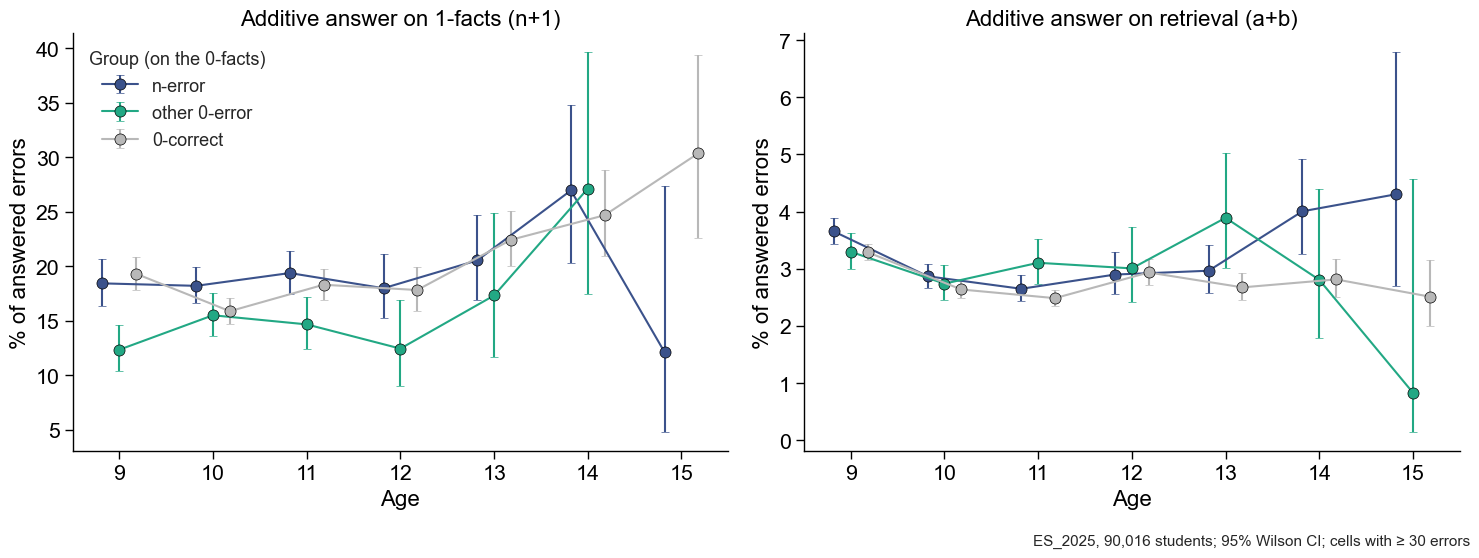

In [5]:
plot_h1(cells, "n_error_h1_additive_by_group_ES_2025")

## 3. H2 — interference from a preceding 1-fact
Unit of analysis: one target 0-fact response (#7 applied). Context = the type of the statement just before it in the
same test (**one**, **zero**, retrieval, division, or **none** = first statement), reference = retrieval.
The comparison is **within student × age** (unit fixed effect) and controls for the fact and for the position in
the test (deciles), SEs clustered by student; a second specification uses a **test** fixed effect (same test, same
moment). Items are drawn at random, so what precedes a 0-fact is close to an experimental manipulation — checked in
the balance table below.

Two confounds are separated:
* **Perseveration** — repeating the previous answer. After `5×1 = 5`, answering `0×5 = 5` is the ×1 rule **and** a
  repetition. `persev` = the previous answer equals n, whatever the previous fact was; it enters the model.
* **Specificity** — a preceding 1-fact might just disturb the next answer. The same model is run on "other error"
  and on any error: the ×1 hypothesis predicts an increase of "= n" only.

In [6]:
zk["prev1c"] = zk.prev1.where(zk.prev1.isin(PREV), "retrieval")
zk["persev"] = zk.prev1_answer.eq(zk.n).astype(np.int8)
zk["pos_dec"] = pd.qcut(zk.pos_in_test.rank(method="first"), 10, labels=False).astype(str)
zk["y_n"], zk["y_other"] = 100 * zk.cls.eq("= n"), 100 * zk.cls.eq("other error")
zk["y_err"] = 100 * zk.cls.ne("correct")
zk["one_in3"] = (zk[["prev1", "prev2", "prev3"]] == "one").any(axis=1).astype(np.int8)
zk["zero_in3"] = (zk[["prev1", "prev2", "prev3"]] == "zero").any(axis=1).astype(np.int8)
zk["one_ok"] = (zk.prev1.eq("one") & zk.prev1_result.eq("Correct")).astype(np.int8)
zk["one_wrong"] = (zk.prev1.eq("one") & zk.prev1_result.ne("Correct")).astype(np.int8)
zk = dummies(zk, "prev1c", PREV[:-1], "p")
PTERMS = ["p_one", "p_zero", "p_division", "p_none"]

balance = zk.groupby("prev1c").agg(trials=("cls", "size"), pos_in_test=("pos_in_test", "mean"),
                                   n_in_test=("n_in_test", "mean"), age=("course_age", "mean"),
                                   n_operand=("n", "mean"), raw_pct_n=("y_n", "mean"),
                                   raw_pct_other=("y_other", "mean")).loc[PREV]
balance.round(2)

,trials,pos_in_test,n_in_test,age,n_operand,raw_pct_n,raw_pct_other
prev1c,,,,,,,
one,35140,15.03,28.49,11.31,5.48,9.10,2.11
zero,37312,15.23,28.83,11.32,5.51,7.66,1.92
division,223493,15.19,28.42,11.34,5.50,7.49,2.39
none,20918,1.00,23.80,11.03,5.49,13.57,2.27
retrieval,128274,14.93,28.26,11.33,5.51,8.46,2.31


In [7]:
rows = []
for y in ("y_n", "y_other", "y_err"):
    for spec, fes in [("unit FE", "unit + operation + pos_dec"), ("test FE", "metric_id + operation + pos_dec")]:
        r = fe(f"{y} ~ {' + '.join(PTERMS)} + persev | {fes}", zk, PTERMS + ["persev"])
        for t, v in r.iterrows():
            rows.append({"outcome": y, "spec": spec, "term": t, **v.to_dict()})
h2 = pd.DataFrame(rows)
base_n = zk.loc[zk.prev1c.eq("retrieval"), "y_n"].mean()
sel = h2.outcome.eq("y_n") & h2.term.isin(["p_one", "persev"])
h2.loc[sel, "OR"] = [or_from_pp(base_n, b) for b in h2.loc[sel, "b"]]
h2.loc[sel, "d"] = d_from_or(h2.loc[sel, "OR"])
h2.loc[sel, "kraft"] = h2.loc[sel, "d"].map(kraft)
h2.set_index(["outcome", "spec", "term"]).round(3)

b     se      p     lo     hi     OR      d  kraft
outcome spec    term                                                              
y_n     unit FE p_one       0.534  0.159  0.001  0.223  0.845  1.069  0.037  small
                p_zero     -0.752  0.136  0.000 -1.019 -0.486    NaN    NaN    NaN
                p_division -0.877  0.087  0.000 -1.048 -0.707    NaN    NaN    NaN
                p_none      0.893  0.287  0.002  0.330  1.456    NaN    NaN    NaN
                persev      0.184  0.156  0.237 -0.121  0.489  1.024  0.013  small
        test FE p_one       0.509  0.165  0.002  0.186  0.832  1.066  0.035  small
                p_zero     -0.714  0.137  0.000 -0.983 -0.446    NaN    NaN    NaN
                p_division -0.805  0.090  0.000 -0.981 -0.629    NaN    NaN    NaN
                p_none      0.778  0.301  0.010  0.189  1.367    NaN    NaN    NaN
                persev     -0.284  0.165  0.085 -0.606  0.039  0.963 -0.021  small
y_other unit FE p_one      -0.170  0.090  0.059 -0.346  0.007    NaN    NaN    NaN
                p_zero     -0.429  0.079  0.000 -0.583 -0.275    NaN    NaN    NaN
                p_division  0.006  0.052  0.901 -0.095  0.108    NaN    NaN    NaN
                p_none      0.217  0.150  0.147 -0.076  0.510    NaN    NaN    NaN
                persev     -0.219  0.095  0.021 -0.406 -0.033    NaN    NaN    NaN
        test FE p_one      -0.105  0.100  0.294 -0.300  0.091    NaN    NaN    NaN
                p_zero     -0.370  0.080  0.000 -0.527 -0.213    NaN    NaN    NaN
                p_division  0.051  0.057  0.369 -0.061  0.163    NaN    NaN    NaN
                p_none     -0.033  0.170  0.848 -0.366  0.300    NaN    NaN    NaN
                persev     -0.404  0.107  0.000 -0.615 -0.194    NaN    NaN    NaN
y_err   unit FE p_one       0.365  0.175  0.037  0.022  0.707    NaN    NaN    NaN
                p_zero     -1.181  0.148  0.000 -1.472 -0.890    NaN    NaN    NaN
                p_division -0.871  0.096  0.000 -1.058 -0.683    NaN    NaN    NaN
                p_none      1.110  0.309  0.000  0.505  1.715    NaN    NaN    NaN
                persev     -0.035  0.170  0.835 -0.368  0.297    NaN    NaN    NaN
        test FE p_one       0.405  0.181  0.026  0.049  0.760    NaN    NaN    NaN
                p_zero     -1.084  0.149  0.000 -1.376 -0.793    NaN    NaN    NaN
                p_division -0.754  0.099  0.000 -0.949 -0.559    NaN    NaN    NaN
                p_none      0.745  0.325  0.022  0.109  1.381    NaN    NaN    NaN
                persev     -0.688  0.177  0.000 -1.035 -0.341    NaN    NaN    NaN

**Mechanism checks.** (a) Window: a 1-fact anywhere in the three previous statements. (b) Was the preceding 1-fact
answered correctly (rule active) or not? (c) The 2 × 2 split of the preceding 1-fact by whether its answer equals
n (rule and repetition coincide) — raw rates. (d) By age (unit FE), Holm over ages.

In [8]:
mech = []
r = fe("y_n ~ one_in3 + zero_in3 + persev | unit + operation + pos_dec", zk, ["one_in3", "zero_in3", "persev"])
mech += [{"check": "window of 3", "term": t, **v.to_dict()} for t, v in r.iterrows()]
r = fe("y_n ~ one_ok + one_wrong + p_zero + p_division + p_none + persev | unit + operation + pos_dec", zk,
       ["one_ok", "one_wrong"])
mech += [{"check": "prev 1-fact right / wrong", "term": t, **v.to_dict()} for t, v in r.iterrows()]
for age in AGES:
    r = fe(f"y_n ~ {' + '.join(PTERMS)} + persev | unit + operation + pos_dec", zk[zk.course_age.eq(age)], ["p_one"])
    mech += [{"check": f"age {age}", "term": "p_one", **r.loc["p_one"].to_dict()}]
mech = pd.DataFrame(mech).set_index(["check", "term"])
ages_idx = [i for i in mech.index if i[0].startswith("age")]
mech.loc[ages_idx, "p_holm_ages"] = holm(mech.loc[ages_idx, "p"].to_numpy())
display(mech.round(3))

split = zk.assign(prev_is_one=zk.prev1c.eq("one"), prev_answer_eq_n=zk.persev.eq(1)) \
          .groupby(["prev_is_one", "prev_answer_eq_n"]).agg(trials=("y_n", "size"), pct_n=("y_n", "mean"))
split.round(2)

b     se      p     lo     hi  p_holm_ages
check                     term                                                     
window of 3               one_in3    0.968  0.097  0.000  0.778  1.159          NaN
                          zero_in3  -0.554  0.083  0.000 -0.716 -0.392          NaN
                          persev    -0.075  0.153  0.623 -0.375  0.225          NaN
prev 1-fact right / wrong one_ok     0.550  0.161  0.001  0.236  0.865          NaN
                          one_wrong  0.256  0.748  0.732 -1.210  1.723          NaN
age 9                     p_one     -1.380  0.795  0.083 -2.939  0.180        0.415
age 10                    p_one      0.519  0.342  0.129 -0.151  1.190        0.415
age 11                    p_one      0.547  0.296  0.064 -0.033  1.127        0.386
age 12                    p_one      1.105  0.429  0.010  0.263  1.946        0.071
age 13                    p_one      0.543  0.366  0.138 -0.175  1.261        0.415
age 14                    p_one      0.687  0.419  0.101 -0.135  1.508        0.415
age 15                    p_one      0.190  0.669  0.776 -1.122  1.502        0.776

trials  pct_n
prev_is_one prev_answer_eq_n               
False       False             385421   8.07
            True               24576   8.87
True        False              31012   9.29
            True                4128   7.66

**Student speed and level (#67).** Controls from `student_controls.sql` (#31), measured on the **retrieval facts
only** (both operands 2-9), so they never see a 0-fact nor a 1-fact: **level** = accuracy, **speed** = mean log RT of
the correct answers (higher = slower). Both z-scored within course age. Students need ≥ 20 non-zero responses (#31).
The unit fixed effect of the main model already absorbs every stable student trait, so speed and level cannot enter
it as main effects. They are used three ways: (a) the main model re-estimated without the unit FE and with the two
controls (plus age), to show the estimate does not hinge on the FE; (b) **moderation** inside the unit FE:
`p_one × level` and `p_one × speed`; (c) the unit-FE estimate inside each quintile of level and of speed.

In [9]:
ctrl = cq("student_controls.sql")[["student_uuid", "course_age", "acc_nr", "mean_lnrt_nr", "n_nr"]]
ctrl = ctrl[ctrl.n_nr.ge(10)]
for c, new in [("acc_nr", "z_level"), ("mean_lnrt_nr", "z_speed")]:
    ctrl[new] = ctrl.groupby("course_age")[c].transform(lambda v: (v - v.mean()) / v.std())
zc = zk.assign(sid=zk.student_uuid.astype(str)).merge(
    ctrl.rename(columns={"student_uuid": "sid"})[["sid", "course_age", "z_level", "z_speed"]],
    on=["sid", "course_age"], how="inner")
zc["one_x_level"], zc["one_x_speed"] = zc.p_one * zc.z_level, zc.p_one * zc.z_speed
print(f"with controls: {len(zc):,} of {len(zk):,} responses ({100 * len(zc) / len(zk):.1f}%), "
      f"{zc.unit.nunique():,} of {zk.unit.nunique():,} units")

rhs = f"{' + '.join(PTERMS)} + persev"
specs = [("unit FE, same sample", f"y_n ~ {rhs} | unit + operation + pos_dec", ["p_one"]),
         ("no unit FE, no controls", f"y_n ~ {rhs} | course_age + operation + pos_dec", ["p_one"]),
         ("no unit FE, + level + speed", f"y_n ~ {rhs} + z_level + z_speed | course_age + operation + pos_dec",
          ["p_one", "z_level", "z_speed"]),
         ("unit FE, moderation", f"y_n ~ {rhs} + one_x_level + one_x_speed | unit + operation + pos_dec",
          ["p_one", "one_x_level", "one_x_speed"])]
ctl = pd.concat({name: fe(f, zc, terms) for name, f, terms in specs}, names=["spec", "term"])
display(ctl.round(3))

qrows = []
for var, lab in [("z_level", "level"), ("z_speed", "speed")]:
    zc[f"q_{lab}"] = pd.qcut(zc[var].rank(method="first"), 5, labels=[f"Q{i}" for i in range(1, 6)])
    for q, d in zc.groupby(f"q_{lab}", observed=True):
        r = fe(f"y_n ~ {rhs} | unit + operation + pos_dec", d, ["p_one"]).loc["p_one"]
        qrows.append({"by": lab, "quintile": q, "base_pct_n": d.loc[d.prev1c.eq("retrieval"), "y_n"].mean(),
                      **r.to_dict()})
quint = pd.DataFrame(qrows).set_index(["by", "quintile"])
quint["rel_pct"] = 100 * quint.b / quint.base_pct_n
quint.round(3)

with controls: 307,466 of 445,137 responses (69.1%), 60,974 of 109,987 units


b     se      p     lo     hi
spec                        term                                          
unit FE, same sample        p_one        0.391  0.174  0.025  0.050  0.733
no unit FE, no controls     p_one        0.486  0.191  0.011  0.112  0.861
no unit FE, + level + speed p_one        0.423  0.190  0.026  0.050  0.795
                            z_level     -2.805  0.106  0.000 -3.013 -2.597
                            z_speed      1.061  0.083  0.000  0.898  1.225
unit FE, moderation         p_one        0.344  0.185  0.063 -0.018  0.707
                            one_x_level  0.104  0.218  0.633 -0.323  0.531
                            one_x_speed -0.185  0.193  0.338 -0.562  0.193

base_pct_n      b     se      p     lo     hi  rel_pct
by    quintile                                                        
level Q1            11.900 -0.233  0.454  0.608 -1.123  0.657   -1.957
      Q2             7.544  0.482  0.406  0.235 -0.314  1.277    6.386
      Q3             5.919  0.685  0.375  0.068 -0.050  1.419   11.565
      Q4             5.594  0.200  0.363  0.582 -0.512  0.911    3.573
      Q5             4.597  0.893  0.341  0.009  0.225  1.562   19.437
speed Q1             4.913  0.755  0.343  0.028  0.082  1.428   15.361
      Q2             5.713  0.448  0.358  0.212 -0.255  1.150    7.835
      Q3             6.647  1.096  0.395  0.006  0.321  1.871   16.493
      Q4             8.040 -0.335  0.403  0.406 -1.124  0.454   -4.166
      Q5            10.124  0.024  0.446  0.957 -0.850  0.898    0.235

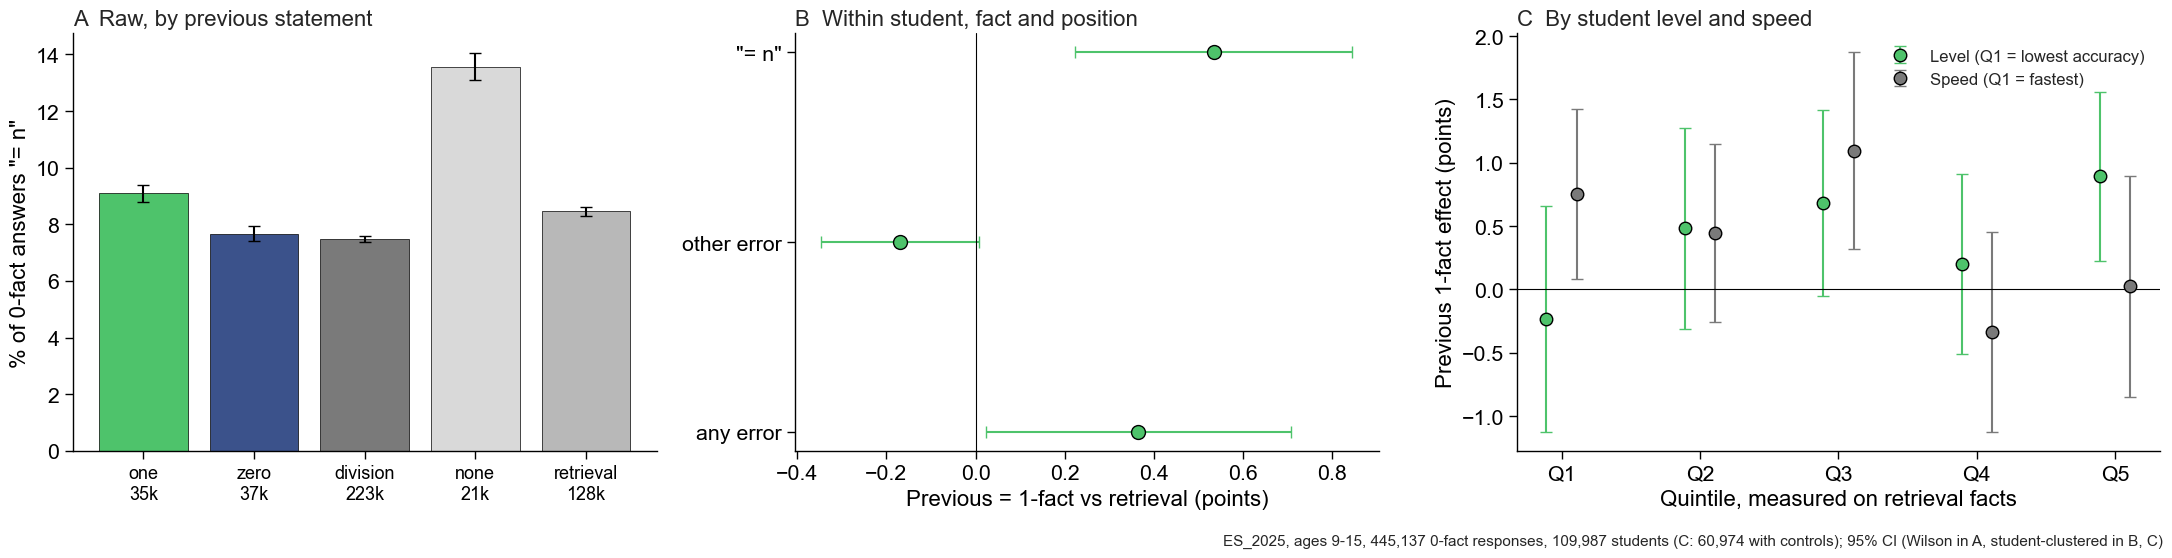

In [10]:
plot_h2(zk, h2, "n_error_h2_prev_one_ES_2025")

## 4. H3 — response time of the "n" answer
Classes on the target 0-facts: **correct**, **= n**, **other error** (answered only; Help has no answer and a
35-40 s RT, #46). **No RT filter (#66):** the direction of "= n" vs correct depends on the 1.2 s filter (#7 drops only
*wrong* answers under 1.2 s and makes errors look slower; a symmetric 1.2 s floor on every answer gives a smaller
positive gap), so the main comparison keeps every answered response. #7 and the symmetric floor are sensitivities.
Model: log RT ~ class | unit + fact, SEs clustered by student; % = exp(b) − 1. Standardised: b / SD of log RT of
correct 0-fact answers (Kraft label). Paired check: per student with both classes, difference of median RT.

In [11]:
SD_LN = np.log(z.loc[z.cls.eq("correct") & z.rt_seconds.gt(0), "rt_seconds"]).std()
rows = []
for mode in ("no filter", "symmetric", "#7"):
    d = rt_data(z, mode)
    r = fe("lnrt ~ c_eq_n + c_other_error | unit + operation", d, ["c_eq_n", "c_other_error"])
    dn = d.copy(); dn = dn[dn.cls.ne("correct")]
    rn = fe("lnrt ~ c_eq_n | unit + operation", dn, ["c_eq_n"])
    for lab, rr in [("= n vs correct", r.loc["c_eq_n"]), ("other error vs correct", r.loc["c_other_error"]),
                    ("= n vs other error", rn.loc["c_eq_n"])]:
        rows.append({"floor": mode, "contrast": lab, "pct": 100 * np.expm1(rr.b), "lo": 100 * np.expm1(rr.lo),
                     "hi": 100 * np.expm1(rr.hi), "p": rr.p, "d": rr.b / SD_LN, "kraft": kraft(rr.b / SD_LN)})
h3 = pd.DataFrame(rows).set_index(["floor", "contrast"])
d3 = rt_data(z, "no filter")
med = d3.groupby(["course_age", "cls"]).rt_seconds.median().unstack()[CLASSES]
med["trials_n"] = d3[d3.cls.eq("= n")].groupby("course_age").size()
display(h3.round(3)); med.round(2)

pct      lo      hi    p      d   kraft
floor     contrast                                                          
no filter = n vs correct          -8.422  -9.293  -7.543  0.0 -0.165  medium
          other error vs correct -53.209 -53.736 -52.676  0.0 -1.426   large
          = n vs other error      60.847  57.989  63.756  0.0  0.892   large
symmetric = n vs correct           5.993   5.061   6.934  0.0  0.109  medium
          other error vs correct -23.261 -24.540 -21.961  0.0 -0.497   large
          = n vs other error      44.066  39.610  48.664  0.0  0.685   large
#7        = n vs correct           8.431   7.460   9.410  0.0  0.152  medium
          other error vs correct -17.630 -19.023 -16.213  0.0 -0.364   large
          = n vs other error      44.066  39.610  48.664  0.0  0.685   large

cls,correct,= n,other error,trials_n
course_age,,,,
9,2.70,2.76,0.84,5439
10,2.40,2.57,0.83,13394
11,2.18,2.38,0.82,12590
12,2.07,2.42,0.83,4650
13,1.90,2.28,0.84,4038
14,1.83,2.17,0.99,1304
15,1.80,2.24,0.98,200


In [12]:
pr = pd.DataFrame([paired(d3, "= n", "correct"), paired(d3, "other error", "correct"),
                   paired(d3, "= n", "other error")]).set_index("contrast")
pr["p_holm"] = holm(pr.p.to_numpy())
by_age = []
for age in AGES:
    r = fe("lnrt ~ c_eq_n + c_other_error | unit + operation", d3[d3.course_age.eq(age)], ["c_eq_n"])
    by_age.append({"course_age": age, **(100 * np.expm1(r.loc["c_eq_n", ["b", "lo", "hi"]])).to_dict(),
                   "p": r.loc["c_eq_n", "p"]})
by_age = pd.DataFrame(by_age).set_index("course_age"); by_age["p_holm"] = holm(by_age.p.to_numpy())
fast = z[z.cls.ne("correct") & z.answer.notna()].assign(fast=lambda d: d.rt_seconds.lt(FLOOR)) \
        .groupby("fast").agg(wrong_answers=("cls", "size"), pct_eq_n=("cls", lambda s: 100 * s.eq("= n").mean()))
display(pr.round(3), by_age.round(3)); fast.round(1)

,students,ratio_median,lo,hi,pct_slower,r_rb,p,p_holm
contrast,,,,,,,,
= n − correct,18390,0.977,0.970,0.985,47.656,-0.073,0.0,0.0
other error − correct,11612,0.398,0.393,0.403,14.373,-0.857,0.0,0.0
= n − other error,6695,1.338,1.297,1.386,69.888,0.648,0.0,0.0


,b,lo,hi,p,p_holm
course_age,,,,,
9,-22.979,-26.009,-19.826,0.000,0.0
10,-13.223,-14.773,-11.645,0.000,0.0
11,-7.798,-9.362,-6.207,0.000,0.0
12,-0.298,-2.647,2.106,0.806,1.0
13,0.057,-2.328,2.500,0.963,1.0
14,-1.490,-5.053,2.207,0.425,1.0
15,2.066,-7.588,12.727,0.687,1.0


,wrong_answers,pct_eq_n
fast,,
False,46530,78.4
True,43134,11.9


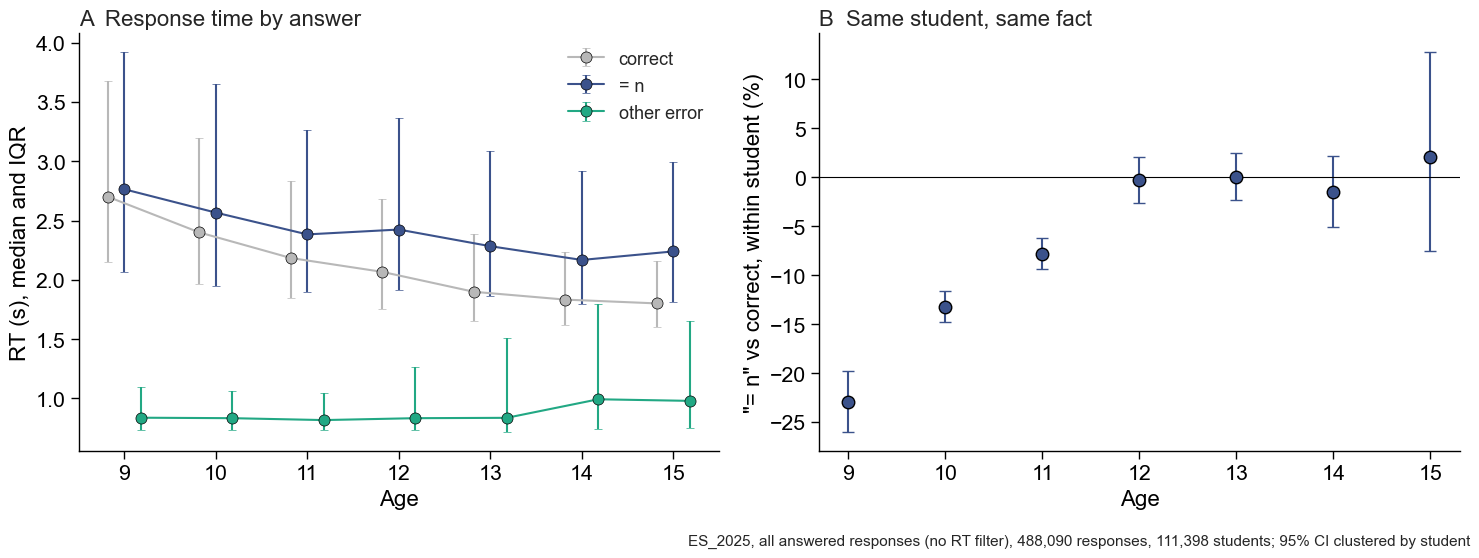

In [13]:
plot_h3(d3, by_age, "n_error_h3_rt_by_answer_ES_2025")

## 5. H4 — copy the other operand
Same groups, cells and adjustment as H1 (#64); only the numerator changes. **Copy** = a wrong answer equal to one of
the operands (#68). On a 1-fact with n ≥ 2 that is the answer **1**: the exact mirror of "= n" on a 0-fact (both
return the operand that the rule says to drop, #44). On retrieval it is an operand intrusion (`3×4 = 4`), reported
as a contrast. Prediction of the copy account: n-error children copy more on the 1-facts given an error, by much more
than they add (H1: +1.5 pp on n+1).
Student level: tetrachoric correlation (bootstrap CI) between "made the n error" and "copied at least once" /
"added at least once" on the 1-facts, among children with an answered 1-fact error.

In [14]:
LAB = {"1-facts (n+1)": "1-facts (copy = 1)", "retrieval (a+b)": "retrieval (operand copy)"}
cc, fc = as_outcome(cells, f, "n_copy", LAB)
h4 = h1_table(cc, g, fc, [(lab, cc[cc.outcome.eq(lab)], "y") for lab in LAB.values()])
display(h4[["students_w_err", "per_100_resp", "pct_of_errors", "O/E", "adj_pp", "lo", "hi", "p", "MH_OR", "d",
            "kraft"]].round(3))

# side by side on the 1-facts: copy vs addition, n-error vs 0-correct
side = pd.DataFrame({"addition (n+1)": h1.loc["1-facts (n+1)"].loc["n-error"],
                     "copy (= 1)": h4.loc["1-facts (copy = 1)"].loc["n-error"]}).T
side["base_0correct"] = [h1.loc[("1-facts (n+1)", "0-correct"), "pct_of_errors"],
                         h4.loc[("1-facts (copy = 1)", "0-correct"), "pct_of_errors"]]
side["rel_increase_pct"] = 100 * side.adj_pp / side.base_0correct
side[["pct_of_errors", "base_0correct", "adj_pp", "lo", "hi", "p", "rel_increase_pct", "MH_OR", "d", "kraft"]].round(3)

students_w_err  per_100_resp  pct_of_errors    O/E  adj_pp      lo     hi      p  MH_OR      d   kraft
outcome                  group                                                                                                                
1-facts (copy = 1)       n-error                4466.0         1.598         27.095  0.917  -3.370  -4.897 -1.842  0.000  0.690 -0.205   large
                         other 0-error          2138.0         2.209         15.928  0.561 -10.338 -12.089 -8.587  0.000    NaN    NaN     NaN
                         0-correct             10159.0         1.110         34.786  1.165     NaN     NaN    NaN    NaN    NaN    NaN     NaN
retrieval (operand copy) n-error               19314.0         2.655         12.671  1.055   0.672   0.377  0.967  0.000  1.111  0.058  medium
                         other 0-error          5251.0         4.326         12.550  1.020  -0.073  -0.526  0.381  0.754    NaN    NaN     NaN
                         0-correct             63964.0         1.558         11.488  0.973     NaN     NaN    NaN    NaN    NaN    NaN     NaN

,pct_of_errors,base_0correct,adj_pp,lo,hi,p,rel_increase_pct,MH_OR,d,kraft
addition (n+1),18.843856,18.482,1.538962,0.23926,2.838664,0.020302,8.326873,1.032367,0.017562,small
copy (= 1),27.095107,34.786,-3.369637,-4.897266,-1.842009,0.000015,-9.686902,0.689687,-0.204828,large


In [15]:
rng = np.random.default_rng(20261109)
u1 = cells[cells.ptype.eq("one")].groupby("unit")[["n_add", "n_copy", "n_err_ans"]].sum()
u1 = u1[u1.n_err_ans.gt(0)].join(g.group)
u1 = u1[u1.group.isin(["n-error", "0-correct"])]
x = u1.group.eq("n-error").astype(int).to_numpy()
tet = pd.DataFrame([{"1-fact error": lab, "children": len(u1), "pct_n_error": 100 * x.mean(),
                     "pct_with_it": 100 * (u1[col] > 0).mean(),
                     **dict(zip(["r_tet", "lo", "hi"], tetrachoric_ci(x, (u1[col] > 0).astype(int).to_numpy(), rng)))}
                    for lab, col in [("copy (= 1)", "n_copy"), ("addition (n+1)", "n_add")]]).set_index("1-fact error")
tet.round(3)

,children,pct_n_error,pct_with_it,r_tet,lo,hi
1-fact error,,,,,,
copy (= 1),14625,30.537,36.116,-0.069,-0.094,-0.043
addition (n+1),14625,30.537,21.436,0.055,0.026,0.095


**One rule for both tables?** "= n" on a 0-fact is the ×1 rule ("give back the other number"); "= 1" on a 1-fact is
the ×0 rule ("give back the special number"). If n-error children run the ×1 rule on both tables, that rule is
*right* on the 1-facts, so given their general level they should be relatively accurate there and rarely answer 1.
Unit-level check: 1-fact error rate by group, controlling for the retrieval error rate (deciles) and age, weighted by
the number of 1-fact responses.

In [16]:
tt = f[f.level.eq("total")].pivot_table(index="unit", columns="ptype", values=["n_resp", "n_err"], aggfunc="sum")
tt.columns = [f"{a}_{b}" for a, b in tt.columns]
tt = tt.dropna().join(g.group)
tt = tt[tt.n_resp_one.ge(2) & tt.n_resp_retrieval.ge(5)].copy()
tt["err_one"] = 100 * tt.n_err_one / tt.n_resp_one
tt["err_ret"] = 100 * tt.n_err_retrieval / tt.n_resp_retrieval
tt["ret_dec"] = pd.qcut(tt.err_ret.rank(method="first"), 10, labels=False).astype(str)
tt["course_age"] = tt.index.str.rsplit("_", n=1).str[1]
tt["student_uuid"] = tt.index.str.rsplit("_", n=1).str[0]
tt = dummies(tt, "group", GROUPS[:2], "g")
onerule = tt.groupby("group").agg(children=("err_one", "size"), err_one=("err_one", "mean"), err_ret=("err_ret", "mean"))
r = fe("err_one ~ g_n_error + g_other_0_error | ret_dec + course_age", tt, ["g_n_error", "g_other_0_error"],
       weights="n_resp_one")
display(onerule.round(2)); r.round(3)

,children,err_one,err_ret
group,,,
0-correct,67990,3.55,14.49
n-error,19019,6.66,22.63
other 0-error,4745,15.26,36.71


,b,se,p,lo,hi
Coefficient,,,,,
g_n_error,0.792,0.088,0.0,0.62,0.964
g_other_0_error,5.144,0.252,0.0,4.65,5.639


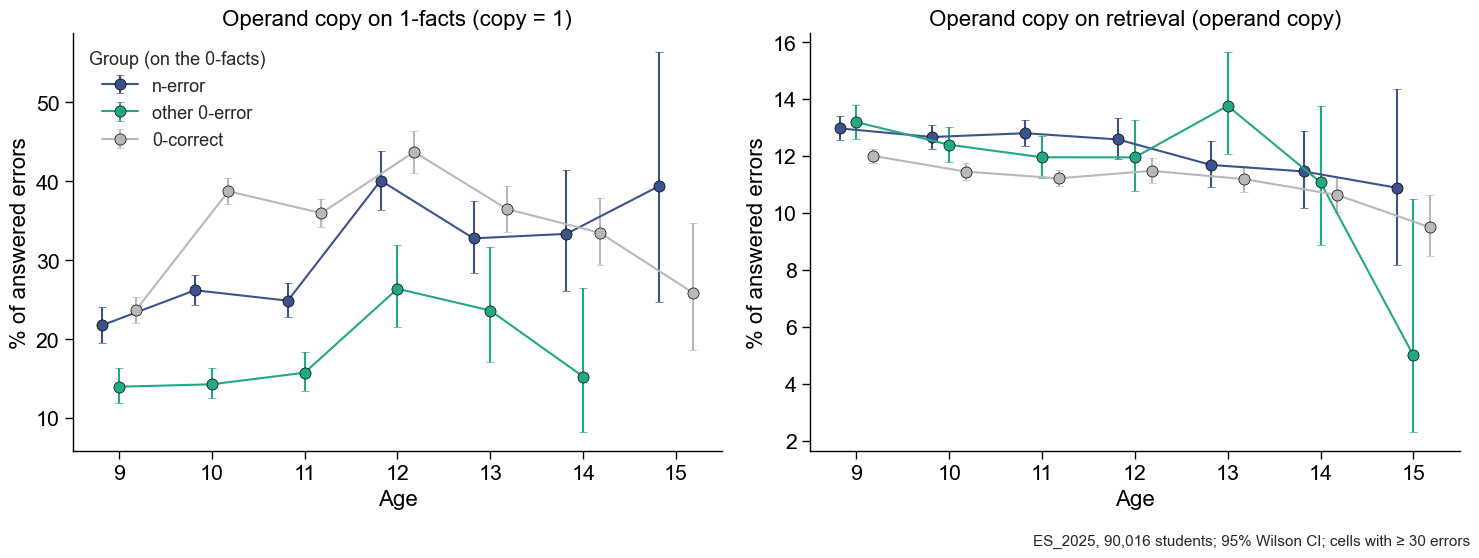

In [17]:
plot_h1(cc, "n_error_h4_copy_by_group_ES_2025", what="Operand copy")

## 6. H5 — stable misconception or slip
Children with ≥ 4 target 0-trials (#7 applied). For each child, k = "= n" answers out of m trials. Finite mixtures of
binomials with K = 1-4 classes (EM, 10 random starts, BIC): a slip model needs one class (everyone shares a low rate);
a misconception model needs a class with a high rate. The same mixture on **other errors** is the control: errors that
are slips should not produce a high-rate class. The fit is checked by simulating each child's m under the fitted
model and comparing the distribution of the n share with the observed one (#69).
Stability: children with ≥ 2 target trials in each of ≥ 2 tests; the n share in two of their tests (Spearman, and
agreement on "n on ≥ half of the trials"). Test order is not used, so the check is symmetric.

In [18]:
SHARE_BINS = [-.01, 0, .25, .5, .75, .999, 1]
SHARE_LABS = ["0", "(0, .25]", "(.25, .5]", "(.5, .75]", "(.75, 1)", "1"]
per = zk.groupby("unit").agg(m=("cls", "size"), k_n=("cls", lambda s: s.eq("= n").sum()),
                             k_other=("cls", lambda s: s.eq("other error").sum()), course_age=("course_age", "first"))
per = per[per.m.ge(4)]
k_n, k_o, m_ = per.k_n.to_numpy(), per.k_other.to_numpy(), per.m.to_numpy()
fits_n, tab_n = fit_mixtures(k_n, m_, rng)
fits_o, tab_o = fit_mixtures(k_o, m_, rng)
best_n, best_o = tab_n.BIC.idxmin(), tab_o.BIC.idxmin()
print(f"{len(per):,} children with >= 4 target 0-trials (median {np.median(m_):.0f} trials)")
display(pd.concat({'"= n"': tab_n, "other error": tab_o}).round(1))

fit_tab = []
for lab, k, fits, best in [('"= n"', k_n, fits_n, best_n), ("other error", k_o, fits_o, best_o)]:
    obs = pd.Series(pd.cut(k / m_, SHARE_BINS, labels=SHARE_LABS)).value_counts(normalize=True).reindex(SHARE_LABS)
    for name, K in [("observed", None), ("K = 1 (slip)", 1), (f"K = {best} (best BIC)", best)]:
        v = obs if K is None else pd.Series(pd.cut(simulate_share(m_, fits[K], rng), SHARE_BINS, labels=SHARE_LABS)) \
            .value_counts(normalize=True).reindex(SHARE_LABS)
        fit_tab.append({"error": lab, "source": name, **(100 * v).to_dict()})
fit_tab = pd.DataFrame(fit_tab).set_index(["error", "source"])
fit_tab.round(1)

52,833 children with >= 4 target 0-trials (median 6 trials)


loglik       BIC                                                        classes
            K                                                                                  
"= n"       1 -57581.3  115173.5                                                 100.0% at 6.8%
            2 -44963.0   89958.6                                  90.3% at 2.7% | 9.7% at 50.0%
            3 -44283.5   88621.3                 84.6% at 1.9% | 12.8% at 28.3% | 2.6% at 81.1%
            4 -44249.8   88575.7  61.8% at 0.6% | 28.7% at 8.1% | 7.6% at 39.4% | 1.9% at 86.1%
other error 1 -21484.6   42980.0                                                 100.0% at 1.8%
            2 -18720.9   37474.4                                  97.3% at 1.0% | 2.7% at 36.1%
            3 -18690.7   37435.7                  96.7% at 0.9% | 3.0% at 27.3% | 0.3% at 67.7%
            4 -18690.3   37456.7  86.4% at 0.7% | 10.7% at 3.0% | 2.7% at 29.5% | 0.3% at 69.7%

0  (0, .25]  (.25, .5]  (.5, .75]  (.75, 1)    1
error       source                                                               
"= n"       observed          76.7      14.7        5.0        1.9       0.6  1.0
            K = 1 (slip)      64.8      31.4        3.8        0.1       0.0  0.0
            K = 4 (best BIC)  76.9      14.4        5.2        1.8       0.9  0.8
other error observed          91.7       6.7        1.2        0.3       0.1  0.1
            K = 1 (slip)      89.2      10.5        0.3        0.0       0.0  0.0
            K = 3 (best BIC)  91.9       6.3        1.2        0.4       0.1  0.1

In [19]:
post = fits_n[best_n]["post"]
per["cls_n"] = post.argmax(1)
hi_cls = int(np.argmax(fits_n[best_n]["p"]))
per["systematic"] = per.cls_n.eq(hi_cls)
by_age = per.groupby("course_age").agg(children=("m", "size"), pct_systematic=("systematic", lambda s: 100 * s.mean()),
                                       pct_any_n=("k_n", lambda s: 100 * (s > 0).mean()),
                                       pct_n_trials=("k_n", "sum"))
by_age["pct_n_trials"] = 100 * by_age.pct_n_trials / per.groupby("course_age").m.sum()
by_age["share_of_n_answers_from_systematic"] = 100 * per[per.systematic].groupby("course_age").k_n.sum() \
    / per.groupby("course_age").k_n.sum()
by_age.loc["all"] = [len(per), 100 * per.systematic.mean(), 100 * (per.k_n > 0).mean(), 100 * k_n.sum() / m_.sum(),
                     100 * per.loc[per.systematic, "k_n"].sum() / k_n.sum()]
by_age.round(1)

,children,pct_systematic,pct_any_n,pct_n_trials,share_of_n_answers_from_systematic
course_age,,,,,
9,1138.0,6.1,24.0,12.1,49.5
10,14467.0,2.1,26.3,8.4,20.8
11,16812.0,1.8,24.3,7.5,20.3
12,7721.0,1.2,23.7,6.4,15.2
13,7692.0,1.1,21.1,5.6,15.4
14,3909.0,0.6,15.0,3.4,12.6
15,1094.0,0.3,8.8,1.8,10.5
all,52833.0,1.7,23.3,6.8,19.4


In [20]:
pm = zk.groupby(["unit", "metric_id"], observed=True).agg(m=("cls", "size"), k=("cls", lambda s: s.eq("= n").sum()))
pm = pm[pm.m.ge(2)].reset_index()
pm = pm[pm.groupby("unit").metric_id.transform("size").ge(2)]
two = pm.groupby("unit").sample(2, random_state=20261109)
two["t"] = two.groupby("unit").cumcount()
w2 = two.assign(share=two.k / two.m).pivot(index="unit", columns="t", values="share")
rho = spearmanr(w2[0], w2[1])
maj = w2.ge(.5)
stab = pd.Series({"children": len(w2), "spearman": rho.statistic, "p": rho.pvalue,
                  "P(≥ half in B | ≥ half in A)": 100 * (maj[0] & maj[1]).sum() / maj[0].sum(),
                  "P(≥ half in B | none in A)": 100 * (w2[0].eq(0) & maj[1]).sum() / w2[0].eq(0).sum(),
                  "P(none in B | none in A)": 100 * (w2[0].eq(0) & w2[1].eq(0)).sum() / w2[0].eq(0).sum()})
stab.round(3)

children                        35311.000
spearman                            0.254
p                                   0.000
P(≥ half in B | ≥ half in A)       30.817
P(≥ half in B | none in A)          5.354
P(none in B | none in A)           90.542
dtype: float64

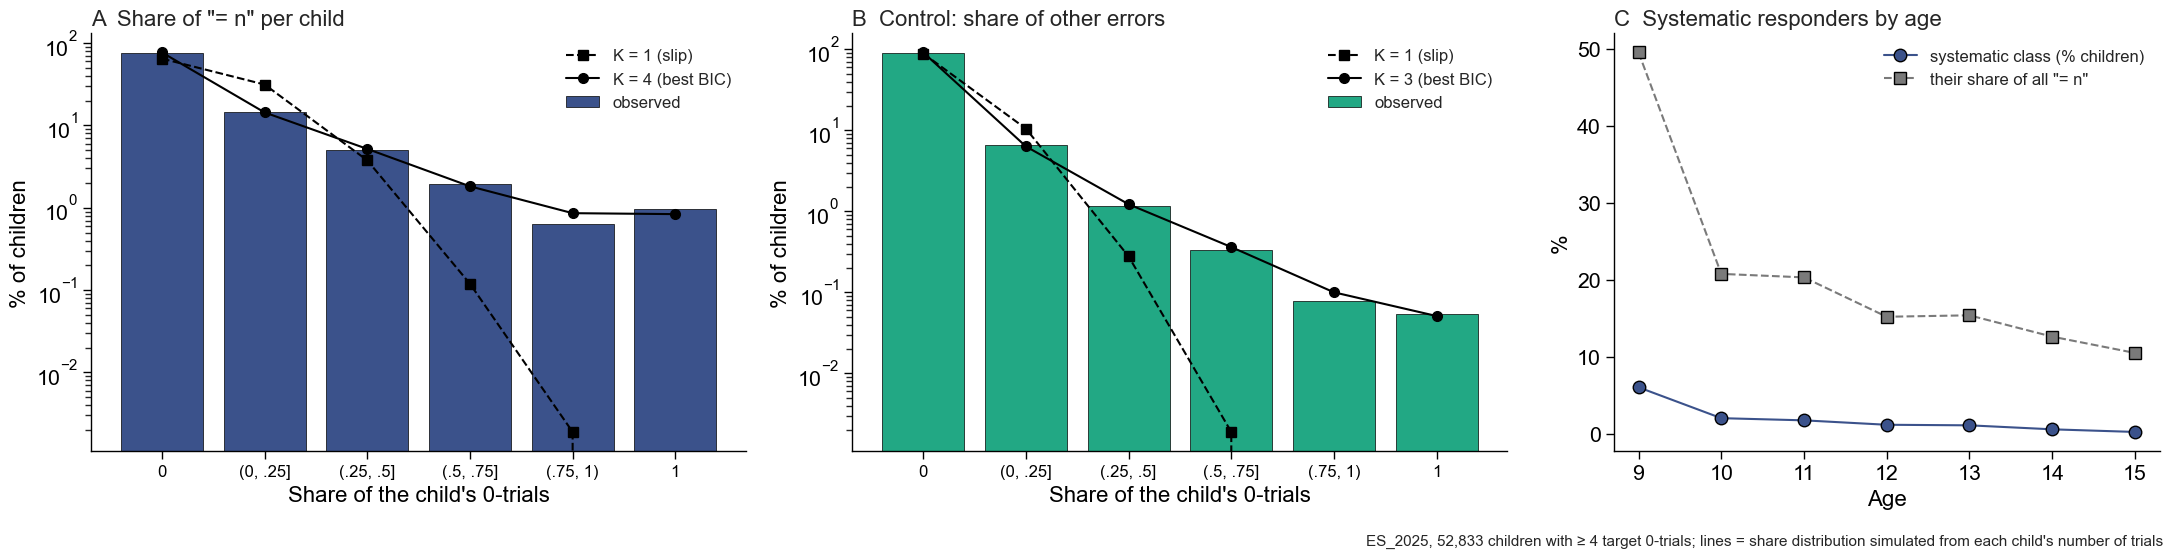

In [21]:
plot_h5(fit_tab, by_age, "n_error_h5_misconception_vs_slip_ES_2025")

## 7. Summary
One line per hypothesis; effect sizes on the SD scale labelled with Kraft (2020): < .05 small, .05-.20 medium,
≥ .20 large. Reading in the Conclusions cell at the end of the notebook.

In [22]:
summary = pd.DataFrame([
    {"check": "H1 additive on 1-facts (n+1), n-error vs 0-correct", "effect": h1.loc[("1-facts (n+1)", "n-error"), "adj_pp"],
     "unit": "pp of errors", "p": h1.loc[("1-facts (n+1)", "n-error"), "p"], "d": h1.loc[("1-facts (n+1)", "n-error"), "d"]},
    {"check": "H1 additive on retrieval (a+b), n-error vs 0-correct", "effect": h1.loc[("retrieval (a+b)", "n-error"), "adj_pp"],
     "unit": "pp of errors", "p": h1.loc[("retrieval (a+b)", "n-error"), "p"], "d": h1.loc[("retrieval (a+b)", "n-error"), "d"]},
    {"check": 'H2 previous 1-fact → "= n" (vs retrieval)', "effect": h2.set_index(["outcome", "spec", "term"]).loc[("y_n", "unit FE", "p_one"), "b"],
     "unit": "pp of answers", "p": h2.set_index(["outcome", "spec", "term"]).loc[("y_n", "unit FE", "p_one"), "p"],
     "d": h2.set_index(["outcome", "spec", "term"]).loc[("y_n", "unit FE", "p_one"), "d"]},
    {"check": 'H2 1-fact in the 3 previous statements → "= n"', "effect": mech.loc[("window of 3", "one_in3"), "b"],
     "unit": "pp of answers", "p": mech.loc[("window of 3", "one_in3"), "p"],
     "d": d_from_or(or_from_pp(base_n, mech.loc[("window of 3", "one_in3"), "b"]))},
    {"check": 'H2 previous answer = n (perseveration)', "effect": h2.set_index(["outcome", "spec", "term"]).loc[("y_n", "unit FE", "persev"), "b"],
     "unit": "pp of answers", "p": h2.set_index(["outcome", "spec", "term"]).loc[("y_n", "unit FE", "persev"), "p"],
     "d": h2.set_index(["outcome", "spec", "term"]).loc[("y_n", "unit FE", "persev"), "d"]},
    {"check": 'H3 RT "= n" vs correct', "effect": h3.loc[("no filter", "= n vs correct"), "pct"], "unit": "% RT",
     "p": h3.loc[("no filter", "= n vs correct"), "p"], "d": h3.loc[("no filter", "= n vs correct"), "d"]},
    {"check": 'H3 RT "= n" vs other error', "effect": h3.loc[("no filter", "= n vs other error"), "pct"], "unit": "% RT",
     "p": h3.loc[("no filter", "= n vs other error"), "p"], "d": h3.loc[("no filter", "= n vs other error"), "d"]},
    {"check": 'H4 copy "= 1" on 1-facts, n-error vs 0-correct', "effect": h4.loc[("1-facts (copy = 1)", "n-error"), "adj_pp"],
     "unit": "pp of errors", "p": h4.loc[("1-facts (copy = 1)", "n-error"), "p"], "d": h4.loc[("1-facts (copy = 1)", "n-error"), "d"]},
    {"check": "H4 operand copy on retrieval, n-error vs 0-correct", "effect": h4.loc[("retrieval (operand copy)", "n-error"), "adj_pp"],
     "unit": "pp of errors", "p": h4.loc[("retrieval (operand copy)", "n-error"), "p"], "d": h4.loc[("retrieval (operand copy)", "n-error"), "d"]},
]).set_index("check")
summary["kraft"] = summary.d.map(kraft)
summary.round(3)

,effect,unit,p,d,kraft
check,,,,,
"H1 additive on 1-facts (n+1), n-error vs 0-correct",1.539,pp of errors,0.020,0.018,small
"H1 additive on retrieval (a+b), n-error vs 0-correct",0.036,pp of errors,0.729,0.042,small
"H2 previous 1-fact → ""= n"" (vs retrieval)",0.534,pp of answers,0.001,0.037,small
"H2 1-fact in the 3 previous statements → ""= n""",0.968,pp of answers,0.000,0.066,medium
H2 previous answer = n (perseveration),0.184,pp of answers,0.237,0.013,small
"H3 RT ""= n"" vs correct",-8.422,% RT,0.000,-0.165,medium
"H3 RT ""= n"" vs other error",60.847,% RT,0.000,0.892,large
"H4 copy ""= 1"" on 1-facts, n-error vs 0-correct",-3.370,pp of errors,0.000,-0.205,large
"H4 operand copy on retrieval, n-error vs 0-correct",0.672,pp of errors,0.000,0.058,medium


### Prevalence of answer profiles and share of "= n" explained
Profiles per child (≥ 4 target 0-trials, same children as H5), the same profiles across two tests of a child (≥ 2
target trials in each), and the share of all "= n" answers attributable to a preceding 1-fact (H2):
attributable = effect (pp) × exposed trials / all "= n" answers.

In [23]:
per["profile"] = per.apply(profile, axis=1)
prof = per.groupby("profile").agg(children=("m", "size"), n_answers=("k_n", "sum"))
prof["pct_children"] = 100 * prof.children / prof.children.sum()
prof["pct_of_n_answers"] = 100 * prof.n_answers / prof.n_answers.sum()
prof_age = pd.crosstab(per.course_age, per.profile, normalize="index").mul(100)

pm2 = zk.assign(ok=zk.cls.eq("correct")).groupby(["unit", "metric_id"], observed=True) \
        .agg(m=("cls", "size"), k=("y_n", lambda v: (v > 0).sum()), e=("ok", lambda v: (~v).sum())).reset_index()
pm2 = pm2[pm2.m.ge(2)]; pm2 = pm2[pm2.groupby("unit").metric_id.transform("size").ge(2)]
pair = pm2.groupby("unit").sample(2, random_state=20261109)
pair["cat"] = np.select([pair.e.eq(0), pair.k.eq(0), pair.k / pair.m < .5], ["correct", "other err", "some n"],
                        "mostly n")


stab2 = pair.groupby("unit").cat.apply(tuple).map(stability).value_counts(normalize=True).mul(100).rename("pct_children")

n_total = zk.cls.eq("= n").sum()
attrib = pd.DataFrame([
    {"exposure": "1-fact immediately before",
     "effect_pp": h2.set_index(["outcome", "spec", "term"]).loc[("y_n", "unit FE", "p_one"), "b"],
     "exposed_trials": int(zk.p_one.sum())},
    {"exposure": "1-fact in previous 3", "effect_pp": mech.loc[("window of 3", "one_in3"), "b"],
     "exposed_trials": int(zk.one_in3.sum())}]).set_index("exposure")
attrib["pct_of_n_answers"] = 100 * attrib.effect_pp / 100 * attrib.exposed_trials / n_total
display(prof.round(1), prof_age.round(1), stab2.round(1).to_frame(), attrib.round(2))

,children,n_answers,pct_children,pct_of_n_answers
profile,,,,
1 always correct,37682,0,71.3,0.0
"2 errors, never n",2848,0,5.4,0.0
3 occasional n (< 50%),9481,12454,17.9,54.6
4 mostly n (≥ 50%),2306,7776,4.4,34.1
5 always n,516,2590,1.0,11.3


profile,1 always correct,"2 errors, never n",3 occasional n (< 50%),4 mostly n (≥ 50%),5 always n
course_age,,,,,
9,68.9,7.1,13.1,5.3,5.6
10,66.5,7.2,19.5,5.6,1.2
11,70.5,5.2,18.8,4.5,1.1
12,71.5,4.8,19.2,3.9,0.6
13,75.1,3.8,16.8,3.7,0.5
14,80.8,4.2,12.6,2.1,0.3
15,88.8,2.4,7.8,0.9,0.1


,pct_children
cat,
stable correct,74.5
"shifter (≥ 50% n in one test, none in the other)",9.3
intermittent n,9.1
"errors, never n",4.7
stable n (≥ 50% in both tests),2.4


,effect_pp,exposed_trials,pct_of_n_answers
exposure,,,
1-fact immediately before,0.53,35140,0.51
1-fact in previous 3,0.97,93181,2.47


## Conclusions

- **H1, addition: not supported as a general strategy.** Given an error, n-error students add as often as 0-correct students: `n+1` on 1-facts 18.8% vs 18.5% of errors (adjusted +1.5 pp [0.2, 2.8], d = .02, small (Kraft)), `a+b` on retrieval 3.1% vs 2.8% (+0.04 pp, p = .73); the higher raw rate per response only reflects more errors of every kind (ES_2025, ages 9–15, 109,987 students).
- **H2, ×1 interference: real but small.** A 1-fact just before raises "= n" by +0.53 pp [0.22, 0.85] on a base of 8.5% (d = .04, small (Kraft)), and a 1-fact anywhere in the previous three by +0.97 pp (d = .07, medium (Kraft)); it is not perseveration (+0.18 pp, p = .24) and explains only 0.5% to 2.5% of all "= n" answers.
- **H3, speed: "= n" is a fluent answer, not a guess.** With no RT filter it is 8% faster than a correct answer of the same student on the same fact (d = −.17, medium (Kraft)), only at ages 9–11 (−23%, −13%, −8%), and 61% slower than other errors (d = .89, large (Kraft)); the sign against correct answers depends on the 1.2 s filter, the distance from guesses does not.
- **H4, copying the other operand: not supported, the effect is reversed.** Given an error on a 1-fact, n-error children answer `1` less often than 0-correct children (27.1% vs 34.8%; adjusted −3.4 pp [−4.9, −1.8], d = −.20, large (Kraft)), so "= 1" on a 1-fact looks like an intrusion of the zero rule made by children who have it.
- **H5, stable belief or slip: mostly confusion, with a small stable core.** A one-rate slip model fails and the best mixture has four classes, the top one 1.9% of children at 86% "= n" (1.7% by posterior), who give 19% of all "= n" answers; 71.3% of children are always correct, 17.9% answer n occasionally and 1.0% always, and across two tests "≥ half n" in one test is followed by "≥ half" in another 31% of the time (5% after a test with none; ρ = .25).
- **Reading.** The "n" answer is what a child does without the zero rule (keep the number, as in ×1), at near-correct speed, not addition and not a general copying habit; always-n falls from 5.6% of children at age 9 to 0.1% at 15, so the zero error is better described as an unstable competition between identity and zero rules than as a misconception held by a group.